# Household income and education in Paraguay

Compare the monthly income per person of two groups of people aged 25 to 60 (inclusive):

- **G1:** their highest degree is primary school (*Educación Escolar Básica*, first and second cycles, up to 6th grade).
- **G2:** they hold a university degree or a postgraduate degree (specialization, master's or doctorate).

For each group: a table of descriptive statistics, a frequency table, and the histograms in one chart. Before any of that, the income column needs cleaning.

**Data.** Microdata from Paraguay's household survey (*Encuesta Permanente de Hogares*, 2016), as distributed in class, with three columns: `P02` (age), `ED06C` (code of the highest degree obtained) and `IPCM` (monthly household income per person, in guaraníes). See [`data/README.md`](../data/README.md).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.options.display.float_format = "{:,.0f}".format

df = pd.read_csv("../data/household-survey-2016.csv")
df.head()

,P02,ED06C,IPCM
0,70,14,"5,578,541,667"
1,64,NaN,"5,578,541,667"
2,45,1,"5,578,541,667"
3,36,1,"5,578,541,667"
4,67,NaN,"9,500,000"


## Clean the income column

A first summary shows a problem:

In [2]:
df["IPCM"].describe()

count          37,713
mean    3,182,876,532
std     2,830,231,903
min            89,076
25%     1,055,363,002
50%     2,314,583,333
75%     5,194,859,068
max     9,996,412,585
Name: IPCM, dtype: float64

The median income would be 2.3 billion guaraníes per person per month, around USD 400,000 at 2016 exchange rates. Most values are inflated. Counting the values above 50 million guaraníes:

In [3]:
big = df["IPCM"] > 50_000_000
print(f"{big.sum():,} of {df['IPCM'].notna().sum():,} values are above 50 million ({big.mean():.0%})")

30,574 of 37,713 values are above 50 million (81%)


Dividing those values by 1000 shows where they come from. Count the decimal places each one has after the division, and compare with the values that were already below 50 million:

In [4]:
def decimals(x):
    text = f"{x:.6f}".rstrip("0")
    return len(text.split(".")[1])

after = (df.loc[big, "IPCM"] / 1000).map(decimals).value_counts()
before = df.loc[~big & df["IPCM"].notna(), "IPCM"].map(decimals).value_counts()
pd.DataFrame({"above 50M, divided by 1000": after, "below 50M": before}).fillna(0).astype(int).sort_index()

,"above 50M, divided by 1000",below 50M
IPCM,,
0,0,3637
1,0,1559
2,0,1943
3,30567,0
5,7,0


Almost every inflated value has exactly three decimals once divided by 1000, and no value below 50 million has three decimals. The original file most likely stored numbers such as `5578541.667`. When it was opened with Spanish regional settings, where the point separates thousands, a point followed by exactly three digits was read as a thousands separator, and `5578541.667` became `5578541667`.

The fix is the rule the spreadsheet used, `=IF(A2>50000000, A2/1000, A2)`. In pandas, `where` keeps the values that meet the condition and replaces the rest:

In [5]:
df["income"] = df["IPCM"].where(df["IPCM"] <= 50_000_000, df["IPCM"] / 1000)
df["income"].describe()

count       37,713
mean     3,559,786
std      2,964,065
min         50,895
25%      1,305,311
50%      2,567,778
75%      5,322,397
max     45,465,935
Name: income, dtype: float64

After the correction the median is 2.57 million guaraníes, about USD 450, which is plausible.

## Select the two groups

The degree codes come from the survey's questionnaire: 3 is primary school, 1 and 8 are university degrees, and 9 and 10 are postgraduate degrees.

In [6]:
age_ok = df["P02"].between(25, 60)

G1 = df.loc[age_ok & (df["ED06C"] == 3), "income"].dropna()
G2 = df.loc[age_ok & df["ED06C"].isin([1, 8, 9, 10]), "income"].dropna()
len(G1), len(G2)

(296, 1510)

## Descriptive statistics

| Statistic | Excel | pandas |
|---|---|---|
| Count | `=COUNT(B2:B296)` | `s.count()` |
| Mean | `=AVERAGE(B2:B296)` | `s.mean()` |
| Maximum, minimum | `=MAX(...)`, `=MIN(...)` | `s.max()`, `s.min()` |
| Range | `=G6-G7` | `s.max() - s.min()` |
| Mode | `=MODE(B2:B296)` | `s.mode()` |
| Median | `=MEDIAN(B2:B296)` | `s.median()` |
| Standard deviation | `=STDEV(B2:B296)` | `s.std()` |

In [7]:
def summary(s):
    """The statistics the course asked for, in the same order as the spreadsheet."""
    return pd.Series({
        "count": s.count(),
        "mean": s.mean(),
        "median": s.median(),
        "mode": s.mode().iloc[0] if s.duplicated().any() else float("nan"),
        "std": s.std(),
        "max": s.max(),
        "min": s.min(),
        "range": s.max() - s.min(),
    })

stats = pd.DataFrame({"G1 primary": summary(G1), "G2 university": summary(G2)})
stats

,G1 primary,G2 university
count,296,"1,510"
mean,"3,113,519","3,886,838"
median,"1,888,273","2,669,523"
mode,"874,811","1,500,000"
std,"2,685,466","3,496,681"
max,"16,507,747","32,491,667"
min,"450,497","375,000"
range,"16,057,249","32,116,667"


People with a university degree have higher incomes: a median of 2.67 million guaraníes against 1.89 million, about 40% more. In both groups the mean is far above the median, because a minority of very high incomes pulls it up; the median describes the typical person better. G2 is also more spread out, with a maximum of 32.5 million against 16.5 million.

## Frequency table by income class

The exercise gave four income classes. In the spreadsheet each one was a count, `=COUNTIF(B:B,"<"&L4)` for the first class and `=COUNTIFS(B:B,">="&K5,B:B,"<"&L5)` for the middle ones. `pd.cut` with `right=False` builds the same classes, each including its lower limit.

In [8]:
bins = [0, 262_768, 686_075, 2_192_839, np.inf]
labels = ["extreme poverty", "poverty", "not poor", "high income"]

counts = pd.DataFrame({
    "G1": pd.cut(G1, bins=bins, labels=labels, right=False).value_counts(sort=False),
    "G2": pd.cut(G2, bins=bins, labels=labels, right=False).value_counts(sort=False),
})
shares = counts / counts.sum()
pd.concat({"people": counts, "share": shares.map("{:.1%}".format)}, axis=1)

people       share       
                    G1   G2     G1     G2
income                                   
extreme poverty      0    0   0.0%   0.0%
poverty              4    8   1.4%   0.5%
not poor           162  557  54.7%  36.9%
high income        130  945  43.9%  62.6%

## Histograms in one chart

The groups have very different sizes (296 and 1,510 people), so the chart on the right, with shares, is the one to compare.

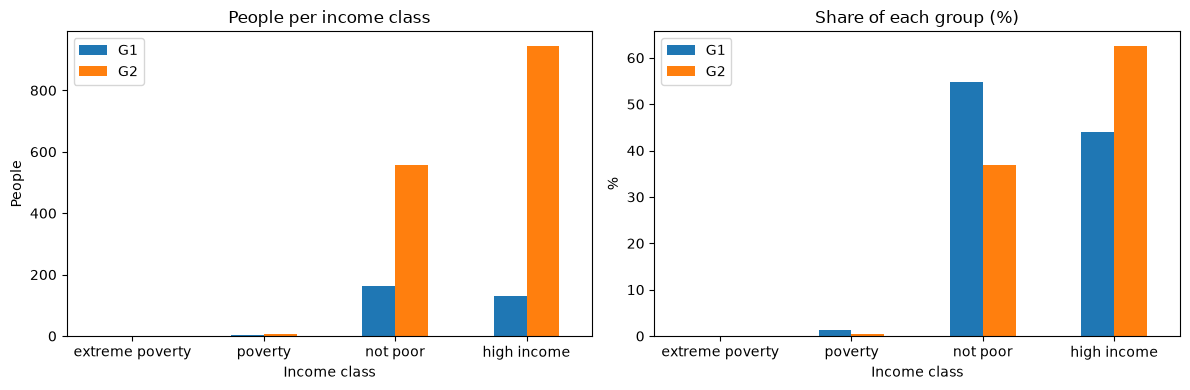

In [9]:
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4))
counts.plot(kind="bar", ax=left, rot=0, title="People per income class")
(shares * 100).plot(kind="bar", ax=right, rot=0, title="Share of each group (%)")
left.set_ylabel("People")
right.set_ylabel("%")
for ax in (left, right):
    ax.set_xlabel("Income class")
plt.tight_layout()
plt.show()

Nobody in either group falls below the first threshold, and very few below the second. The difference is at the top: 63% of the university graduates are in the highest class, against 44% of the people with primary school only.

## Notes

- The spreadsheet version of this exercise listed 295 people in G1 and 781 in G2. One G1 row was missed, and G2 held only part of the 1,510 rows that meet the conditions, most likely because the filtered list was copied incompletely. The filters above take every matching row.
- Seven values above 50 million have two decimals instead of looking like inflated whole numbers (for example 93,991,666.67). They are probably real high incomes that the rule divides by 1000 anyway. None of them falls in G1 or G2, so the results above do not change; a stricter rule would also check the decimals.
- `IPCM` is a household figure: every member of a household gets the same value. That is why a mode exists at all for a continuous variable (the most repeated value belongs to a large household), and why the rows are not independent observations.
- The class limits were given by the exercise. They are not necessarily the official poverty lines for 2016.